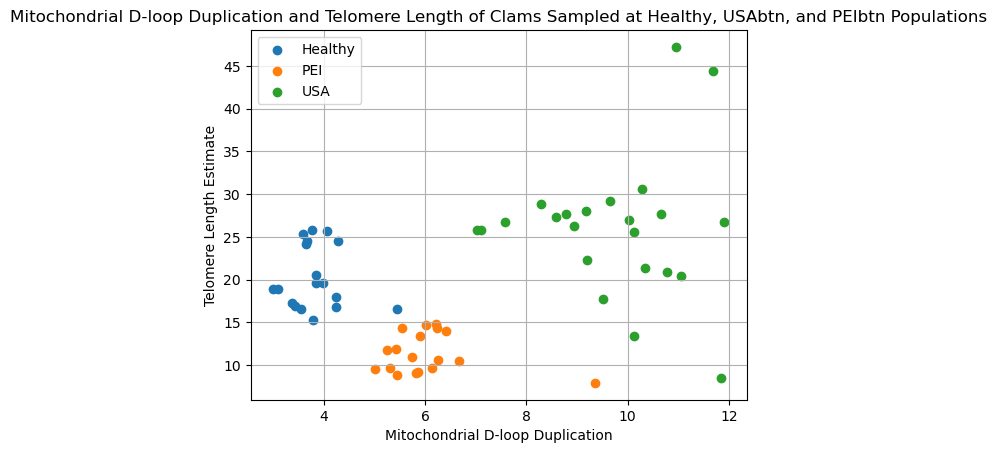

In [3]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd

#having python read the data 
telomere_data = pd.read_csv("telomerelength.csv") 
mdloop_data = pd.read_csv("bivalvemdloop.csv")

#grouping the data by groups belonging to regions "USA", "PEI", and healthy 
merged_data = pd.merge(telomere_data, mdloop_data, on="sample") 
merged_data.columns = merged_data.columns.str.strip()

#as both data have the same groups and python will name it to different things, we need to redefine merged_data that contains only one 
#set of groups 
merged_data = merged_data.rename(columns={"region_x": "region"}).drop(columns=["region_y"]) 

#plotting the graph
for region, group in merged_data.groupby("region"):
    plt.scatter(group["dloop_dup"], group["LENGTH_ESTIMATE"], label=region, alpha=1)

#labelling the graph 
plt.xlabel("Mitochondrial D-loop Duplication")
plt.ylabel("Telomere Length Estimate")
plt.title("Mitochondrial D-loop Duplication and Telomere Length of Clams Sampled at Healthy, USAbtn, and PEIbtn Populations")
plt.legend()
plt.grid(True)


Mean Telomere Length by Region:
    region  LENGTH_ESTIMATE
0      PEI        11.404516
1  Healthy        20.274978
2      USA        26.058679

Regression Equation: y = 7.327x + 11.919
Mean Squared Error (MSE): 0.529
R-squared (R²): 0.985


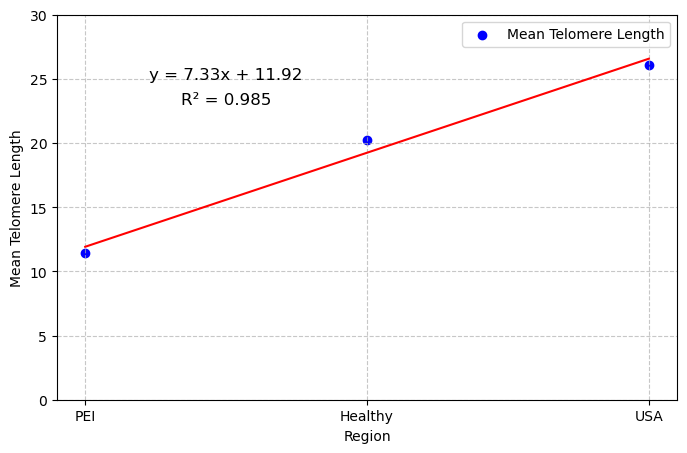

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('telomerelength.csv')

#calculating mean telomere length by region
mean_by_region = df.groupby('region')['LENGTH_ESTIMATE'].mean().reset_index()

#defining the order established from the scatterplot, with PEI=0, Healthy=1, USA=2
region_order = ["PEI", "Healthy", "USA"]
mean_by_region = mean_by_region.set_index('region').loc[region_order].reset_index()

#assign numerical for each region in the x-values (0, 1, 2)
X = mean_by_region.index.values.reshape(-1, 1)  
y = mean_by_region['LENGTH_ESTIMATE'].values   #dependent variable

#establishing the model as linear regression and fit the linear regression model
model = LinearRegression()  
model.fit(X, y)
y_pred = model.predict(X) #predicting values for linear regression 

#calculate mean squared error and r2
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("Mean Telomere Length by Region:")
print(mean_by_region[['region', 'LENGTH_ESTIMATE']])
print(f"\nRegression Equation: y = {model.coef_[0]:.3f}x + {model.intercept_:.3f}")
print(f"Mean Squared Error (MSE): {mse:.3f}")
print(f"R-squared (R²): {r2:.3f}")

# plotting
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', label='Mean Telomere Length')
plt.plot(X, y_pred, color='red')

equation_text = f'y = {model.coef_[0]:.2f}x + {model.intercept_:.2f}'
r2_text = f'R² = {r2:.3f}'
plt.text(0.5, 25, equation_text, fontsize=12, ha='center')  #adjusting position (x=0.5, y=25)
plt.text(0.5, 23, r2_text, fontsize=12, ha='center')       #adjusting position (x=0.5, y=23)
plt.xticks(X.flatten(), region_order)
plt.xlabel("Region")
plt.ylabel("Mean Telomere Length")
plt.legend()
plt.ylim(0, 30)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Mean Mitochondrial D-loop Duplications by Region:
    region  dloop_dup
0  Healthy   3.824888
1      PEI   6.033510
2      USA   9.722470

Regression Equation: y = 2.949x + 3.578
Mean Squared Error (MSE): 0.122
R-squared (R²): 0.979


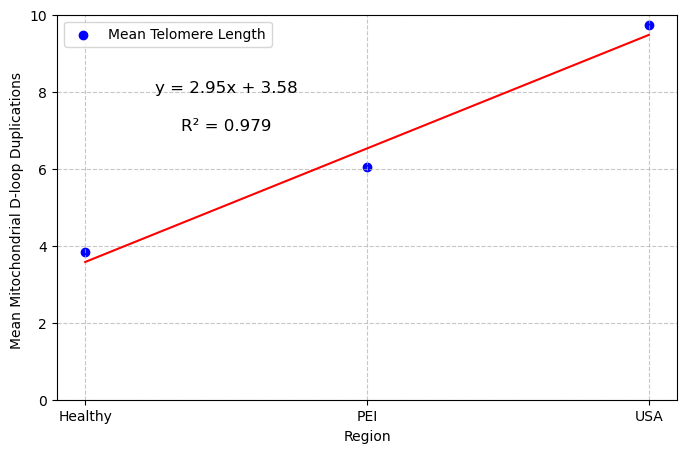

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('bivalvemdloop.csv')

#calculate mean d-loop duplications by region
mean_by_region = df.groupby('region')['dloop_dup'].mean().reset_index()

#defining the desired order (healthy=0, PEI=1, USA=2)
region_order = ["Healthy","PEI", "USA"]
mean_by_region = mean_by_region.set_index('region').loc[region_order].reset_index()

#assign numerical x-values (0, 1, 2) to our indepndent variables
X = mean_by_region.index.values.reshape(-1, 1)  # Features must be 2D for sklearn
y = mean_by_region['dloop_dup'].values   # Target values

# establishing linear regression model and fit the linear regression model
model = LinearRegression()  
model.fit(X, y)
y_pred = model.predict(X)

#calculate MSE and R²
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

#print results
print("Mean Mitochondrial D-loop Duplications by Region:")
print(mean_by_region[['region', 'dloop_dup']])
print(f"\nRegression Equation: y = {model.coef_[0]:.3f}x + {model.intercept_:.3f}")
print(f"Mean Squared Error (MSE): {mse:.3f}")
print(f"R-squared (R²): {r2:.3f}")

# plotting
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', label='Mean Telomere Length')
plt.plot(X, y_pred, color='red')

equation_text = f'y = {model.coef_[0]:.2f}x + {model.intercept_:.2f}'
r2_text = f'R² = {r2:.3f}'
plt.text(0.5, 8, equation_text, fontsize=12, ha='center')  
plt.text(0.5, 7, r2_text, fontsize=12, ha='center')       
plt.xticks(X.flatten(), region_order)
plt.xlabel("Region")
plt.ylabel("Mean Mitochondrial D-loop Duplications ")
plt.legend()
plt.ylim(0, 10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Optimization terminated successfully.
         Current function value: 0.233652
         Iterations: 20
         Function evaluations: 22
         Gradient evaluations: 22
                             OrderedModel Results                             
Dep. Variable:                 region   Log-Likelihood:                -13.785
Model:                   OrderedModel   AIC:                             33.57
Method:            Maximum Likelihood   BIC:                             39.80
Date:                Thu, 03 Apr 2025                                         
Time:                        03:17:44                                         
No. Observations:                  59                                         
Df Residuals:                      56                                         
Df Model:                           1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

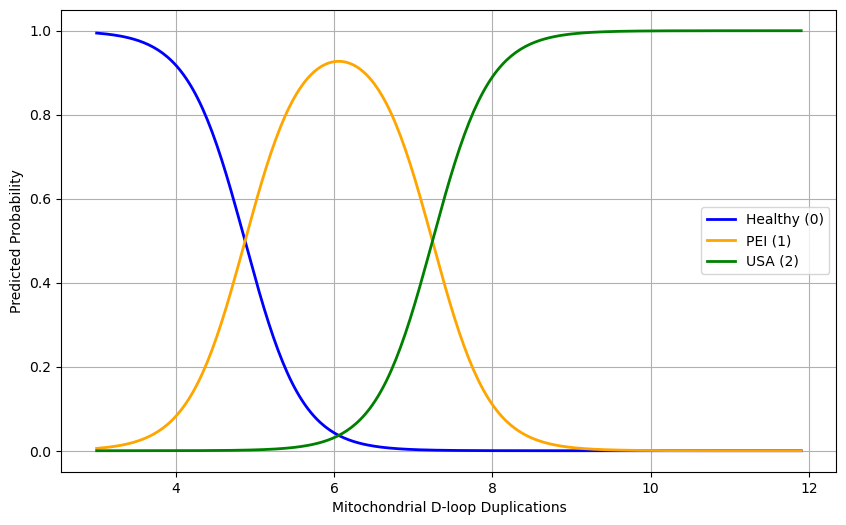

In [5]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv('bivalvemdloop.csv')

#assigning the regions to ordered categorical values
data['region'] = data['region'].map({'Healthy': 0, 'PEI': 1, 'USA': 2})

#define the dependent and independent variables
y = data['region']
X = data[['dloop_dup']]

#fit the ordered logistic regression model without a constant
model = OrderedModel(y, X, distr='logit')
result = model.fit(method='bfgs')
print(result.summary()) #print summary

#generate a range of values for dloop_dup to plot the predicted probabilities
dloop_dup_range = np.linspace(data['dloop_dup'].min(), data['dloop_dup'].max(), 300)
X_plot = pd.DataFrame({'dloop_dup': dloop_dup_range})

#predict probabilities for each region
pred_probs = result.predict(X_plot)
plt.figure(figsize=(10, 6))
plt.plot(dloop_dup_range, pred_probs[0], label='Healthy (0)', color='blue', linewidth=2)
plt.plot(dloop_dup_range, pred_probs[1], label='PEI (1)', color='orange', linewidth=2)
plt.plot(dloop_dup_range, pred_probs[2], label='USA (2)', color='green', linewidth=2)
plt.xlabel('Mitochondrial D-loop Duplications')
plt.ylabel('Predicted Probability')
plt.legend()
plt.grid(True)
plt.show()

Optimization terminated successfully.
         Current function value: 0.626776
         Iterations: 15
         Function evaluations: 18
         Gradient evaluations: 18
                             OrderedModel Results                             
Dep. Variable:                 region   Log-Likelihood:                -36.980
Model:                   OrderedModel   AIC:                             79.96
Method:            Maximum Likelihood   BIC:                             86.19
Date:                Thu, 03 Apr 2025                                         
Time:                        03:22:53                                         
No. Observations:                  59                                         
Df Residuals:                      56                                         
Df Model:                           1                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------

<Figure size 1000x600 with 0 Axes>

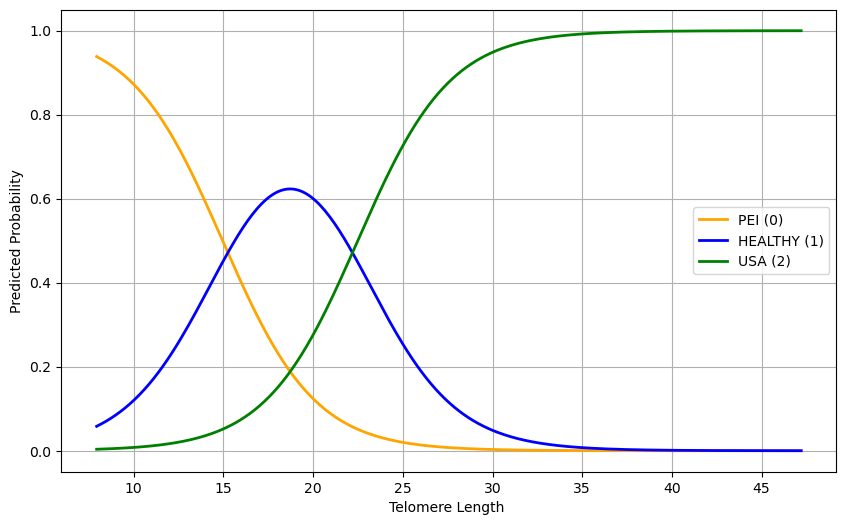

In [7]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv('telomerelength.csv')

#assigning the regions to ordered categorical values
data['region'] = data['region'].map({'PEI': 0, 'Healthy': 1, 'USA': 2})

#define the dependent and independent variables
y = data['region']
X = data[['LENGTH_ESTIMATE']]

#create and fit the ordered logistic regression model without a constant
model = OrderedModel(y, X, distr='logit')
result = model.fit(method='bfgs')
print(result.summary())

plt.figure(figsize=(10, 6))

#generate a range of values for dloop_dup to plot the predicted probabilities
telomerelen = np.linspace(data['LENGTH_ESTIMATE'].min(), data['LENGTH_ESTIMATE'].max(), 300)
X_plot = pd.DataFrame({'LENGTH_ESTIMATE': telomerelen})

#predict probabilities for each region
pred_probs = result.predict(X_plot)
plt.figure(figsize=(10, 6))
plt.plot(telomerelen, pred_probs[0], label='PEI (0)', color='orange', linewidth=2)
plt.plot(telomerelen, pred_probs[1], label='HEALTHY (1)', color='blue', linewidth=2)
plt.plot(telomerelen, pred_probs[2], label='USA (2)', color='green', linewidth=2)
plt.xlabel('Telomere Length ')
plt.ylabel('Predicted Probability')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error 

df = pd.read_csv('bivalvedrug2.csv') 

df = df[['drug','time (h)', 'reduction_rate', 'clam']]

df = df.dropna() 

df = pd.get_dummies(df, columns = ['drug','clam'], drop_first = True) 

X = df.drop('reduction_rate', axis = 1)
y = df['reduction_rate']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()

model.fit (X_train, y_train) 

y_pred = model.predict(X_test) 

mse = mean_squared_error(y_test,y_pred) 

coefficients = model.coef_
intercept = model.intercept_

print("Coefficients:", coefficients)
print("Intercept:", intercept)
print(f"Mean Squared Error: {mse}") 

Coefficients: [ -0.87205568  18.19950213  23.09531518  -4.11584932 -18.00845366]
Intercept: 39.38563992333234
Mean Squared Error: 439.29696294311447
